Predicting Stock Market Prices	Design and compute a robust suite of advanced technical indicators?including Simple and Exponential Moving Averages, Relative Strength Index (RSI), Moving Average Convergence Divergence (MACD), and Bollinger Bands?to capture momentum, trend, and volatilit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset and sort chronologically
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

print(f"Dataset loaded: {len(df)} rows ({df['Date'].min().date()} to {df['Date'].max().date()})")
df[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']].head()

Dataset loaded: 100 rows (2025-01-02 to 2025-05-14)


,Date,Open,High,Low,Close,Volume
0,2025-01-02,377.53,386.12,374.68,381.88,97077442
1,2025-01-03,372.39,377.55,371.43,376.36,85746412
2,2025-01-06,377.69,381.99,373.44,380.68,56893889
3,2025-01-07,387.26,390.45,385.32,386.06,76990555
4,2025-01-08,372.81,379.96,368.15,375.53,100413036


In [2]:
# 1. Trend Indicators: Simple & Exponential Moving Averages
df['SMA_10'] = df['Close'].rolling(window=10).mean()
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['EMA_12'] = df['Close'].ewm(span=12, adjust=False).mean()
df['EMA_26'] = df['Close'].ewm(span=26, adjust=False).mean()

# 2. Momentum Indicator: 14-Day Relative Strength Index (Wilder's Smoothing)
delta = df['Close'].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
rs = avg_gain / avg_loss
df['RSI_14'] = 100 - (100 / (1 + rs))

# 3. Trend & Momentum Crossover: MACD (12, 26, 9)
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 4. Volatility & Price Envelope: Bollinger Bands (20-day SMA ± 2 Std Dev)
df['BB_Middle'] = df['SMA_20']
rolling_std_20 = df['Close'].rolling(window=20).std()
df['BB_Upper'] = df['BB_Middle'] + (2 * rolling_std_20)
df['BB_Lower'] = df['BB_Middle'] - (2 * rolling_std_20)
df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle']
df['BB_PctB'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

print("--- Technical Indicator Summary Statistics ---")
print(df[['RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Width', 'BB_PctB']].describe().round(2).to_string())

print("\n--- Latest 5 Trading Days ---")
print(df[['Date', 'Close', 'SMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Lower']].tail().round(2).to_string(index=False))

--- Technical Indicator Summary Statistics ---
       RSI_14    MACD  MACD_Signal  MACD_Hist  BB_Width  BB_PctB
count   86.00  100.00       100.00     100.00     81.00    81.00
mean    50.60    1.59         1.64      -0.05      0.06     0.61
std      9.85    3.11         2.84       1.04      0.01     0.29
min     31.58   -3.99        -2.91      -1.88      0.03    -0.00
25%     43.31   -0.54        -0.60      -0.99      0.05     0.40
50%     50.32    0.95         0.79       0.02      0.06     0.65
75%     57.83    4.51         4.34       0.73      0.07     0.79
max     73.09    8.09         6.99       2.13      0.09     1.37

--- Latest 5 Trading Days ---
      Date  Close  SMA_20  RSI_14  MACD  MACD_Signal  BB_Upper  BB_Lower
2025-05-08 406.64  403.04   53.26 -1.45        -1.47    411.06    395.02
2025-05-09 406.30  403.20   52.80 -1.05        -1.38    411.34    395.05
2025-05-12 404.17  403.49   49.86 -0.89        -1.28    411.31    395.66
2025-05-13 403.93  403.62   49.52 -0.77      

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_924\280112366.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df[['Date', 'Close', 'SMA_20', 'RSI_14', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Lower']].tail().round(2).to_string(index=False))


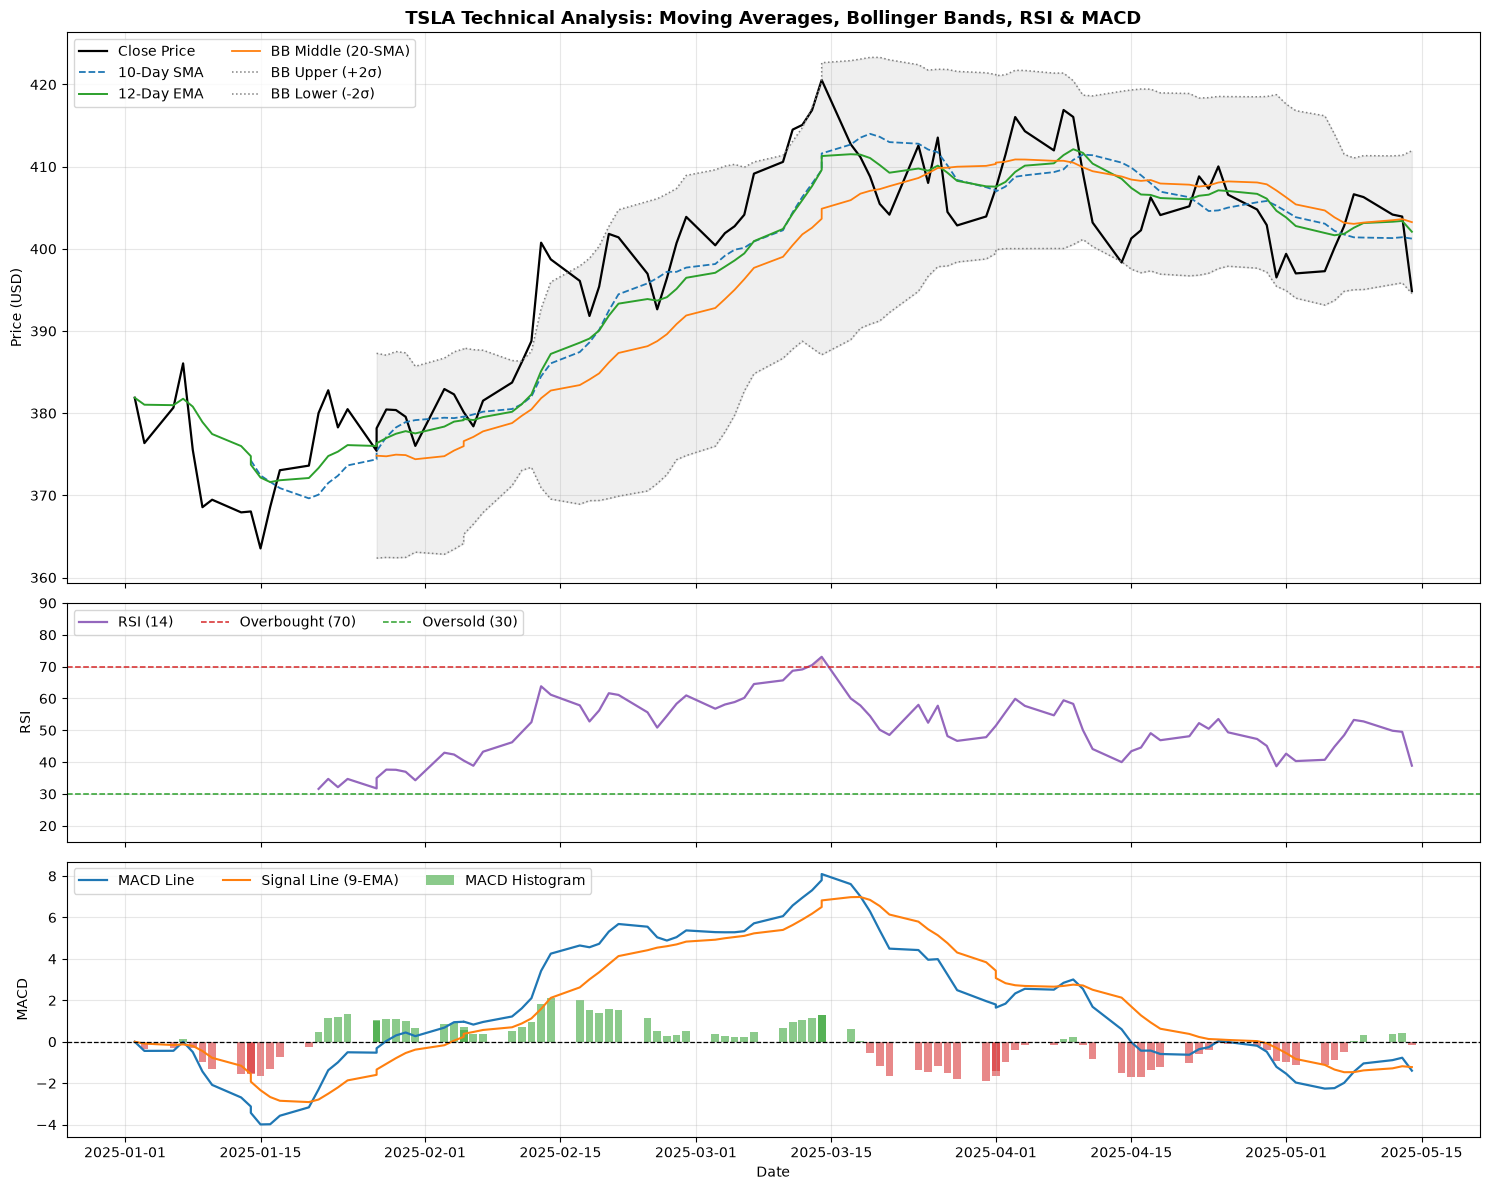

In [3]:
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, figsize=(15, 12), sharex=True,
    gridspec_kw={'height_ratios': [3, 1.3, 1.5]}
)

# Panel 1: Price, Moving Averages & Bollinger Bands
ax1.plot(df['Date'], df['Close'], label='Close Price', color='black', linewidth=1.6)
ax1.plot(df['Date'], df['SMA_10'], label='10-Day SMA', color='#1f77b4', linestyle='--', linewidth=1.3)
ax1.plot(df['Date'], df['EMA_12'], label='12-Day EMA', color='#2ca02c', linewidth=1.4)
ax1.plot(df['Date'], df['BB_Middle'], label='BB Middle (20-SMA)', color='#ff7f0e', linewidth=1.3)
ax1.plot(df['Date'], df['BB_Upper'], label='BB Upper (+2σ)', color='gray', linestyle=':', linewidth=1.1)
ax1.plot(df['Date'], df['BB_Lower'], label='BB Lower (-2σ)', color='gray', linestyle=':', linewidth=1.1)
ax1.fill_between(df['Date'], df['BB_Lower'], df['BB_Upper'], color='gray', alpha=0.12)
ax1.set_title('TSLA Technical Analysis: Moving Averages, Bollinger Bands, RSI & MACD', fontsize=13, fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.legend(loc='upper left', ncol=2)
ax1.grid(True, alpha=0.3)

# Panel 2: Relative Strength Index (RSI-14)
ax2.plot(df['Date'], df['RSI_14'], label='RSI (14)', color='#9467bd', linewidth=1.6)
ax2.axhline(70, color='#d62728', linestyle='--', linewidth=1.1, label='Overbought (70)')
ax2.axhline(30, color='#2ca02c', linestyle='--', linewidth=1.1, label='Oversold (30)')
ax2.fill_between(df['Date'], 70, df['RSI_14'], where=(df['RSI_14'] >= 70), color='#d62728', alpha=0.2)
ax2.fill_between(df['Date'], 30, df['RSI_14'], where=(df['RSI_14'] <= 30), color='#2ca02c', alpha=0.2)
ax2.set_ylabel('RSI')
ax2.set_ylim(15, 90)
ax2.legend(loc='upper left', ncol=3)
ax2.grid(True, alpha=0.3)

# Panel 3: MACD (12, 26, 9) & Histogram
ax3.plot(df['Date'], df['MACD'], label='MACD Line', color='#1f77b4', linewidth=1.6)
ax3.plot(df['Date'], df['MACD_Signal'], label='Signal Line (9-EMA)', color='#ff7f0e', linewidth=1.5)
hist_colors = np.where(df['MACD_Hist'] >= 0, '#2ca02c', '#d62728')
ax3.bar(df['Date'], df['MACD_Hist'], color=hist_colors, alpha=0.55, width=0.8, label='MACD Histogram')
ax3.axhline(0, color='black', linestyle='--', linewidth=0.9)
ax3.set_ylabel('MACD')
ax3.set_xlabel('Date')
ax3.legend(loc='upper left', ncol=3)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()